# Análisis Exploratorio de Datos (EDA)

## Sistema híbrido de aprendizaje automático y optimización combinatoria para la planificación de rutas de recolección de residuos sólidos urbanos

**Autores:** Grimaldo René Abarca Urbano y Jorge Raúl Valega Marquina  
**Programa:** Maestría en Inteligencia Artificial – Universidad Nacional de Ingeniería (UNI)

> **Nota:** La base utilizada en esta entrega es sintética y tiene fines académicos. Su estructura replica las variables previstas en el proyecto de tesis. No representa datos oficiales de la Municipalidad Distrital de Yarinacocha.


## 1. Objetivo del EDA

El análisis exploratorio tiene como finalidad conocer la estructura y calidad de los datos, identificar valores faltantes y duplicados, revisar la distribución de las variables operativas y explorar relaciones útiles para una posterior etapa de aprendizaje automático y optimización de rutas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [2]:
# Carga de datos
ruta = Path("../data/residuos_yarinacocha_2026.csv")
df = pd.read_csv(ruta)

df.head()


,fecha,codigo_ruta,vehiculo,sector,hora_salida,hora_llegada,duracion_min,distancia_km,combustible_l,costo_operativo_soles,capacidad_vehicular_kg,residuos_recolectados_kg,puntos_programados,puntos_atendidos,cumplimiento_pct,latitud,longitud,incidencia
0,2026-01-01,R003,VH04,San José,06:20,09:46,206,41.95,13.57,348.39,6000,"3,503.32",40,40,100.00,-8.38,-74.60,Demora operativa
1,2026-01-01,R004,VH02,La Restinga,07:27,09:57,150,30.83,8.37,228.71,5000,"3,861.81",45,45,100.00,-8.31,-74.54,Ninguna
2,2026-01-02,R004,VH01,La Restinga,06:26,08:56,150,38.47,11.82,302.69,4500,"3,398.72",39,39,100.00,-8.36,-74.60,Ninguna
3,2026-01-02,R005,VH03,Las Palmeras,07:17,10:11,174,41.37,13.01,327.39,5500,"4,348.02",42,42,100.00,-8.35,-74.57,Ninguna
4,2026-01-03,R005,VH02,Las Palmeras,06:27,09:34,187,48.09,13.47,336.99,5000,"4,619.23",33,33,100.00,-8.37,-74.60,Ninguna


## 2. Dimensiones y estructura de la base

In [3]:
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])
print("\nTipos de datos:")
print(df.dtypes)


Número de registros: 733
Número de variables: 18

Tipos de datos:
fecha                        object
codigo_ruta                  object
vehiculo                     object
sector                       object
hora_salida                  object
hora_llegada                 object
duracion_min                  int64
distancia_km                float64
combustible_l               float64
costo_operativo_soles       float64
capacidad_vehicular_kg        int64
residuos_recolectados_kg    float64
puntos_programados            int64
puntos_atendidos              int64
cumplimiento_pct            float64
latitud                     float64
longitud                    float64
incidencia                   object
dtype: object


## 3. Calidad de datos

In [4]:
# Valores faltantes
faltantes = df.isnull().sum().sort_values(ascending=False)
faltantes[faltantes > 0]


combustible_l            6
costo_operativo_soles    4
latitud                  3
longitud                 3
dtype: int64

In [5]:
# Registros duplicados
duplicados = df.duplicated().sum()
print("Registros duplicados:", duplicados)


Registros duplicados: 3


### Criterio de depuración
Los registros duplicados se eliminan. Los valores faltantes no se imputan automáticamente en esta etapa, porque en una base institucional real primero deberían verificarse con la documentación operativa correspondiente.


In [6]:
df_limpio = df.drop_duplicates().copy()

print("Registros antes de depurar:", len(df))
print("Registros después de eliminar duplicados:", len(df_limpio))


Registros antes de depurar: 733
Registros después de eliminar duplicados: 730


## 4. Estadística descriptiva

In [7]:
variables_numericas = [
    "duracion_min",
    "distancia_km",
    "combustible_l",
    "costo_operativo_soles",
    "capacidad_vehicular_kg",
    "residuos_recolectados_kg",
    "puntos_programados",
    "puntos_atendidos",
    "cumplimiento_pct"
]

df_limpio[variables_numericas].describe().T


,count,mean,std,min,25%,50%,75%,max
duracion_min,730.00,199.62,44.35,150.00,160.00,191.00,225.75,431.00
distancia_km,730.00,40.30,6.79,21.76,35.85,39.82,44.99,60.27
combustible_l,724.00,12.53,2.38,7.07,10.96,12.29,14.05,23.27
costo_operativo_soles,726.00,329.32,52.34,216.40,294.37,323.31,361.69,554.39
capacidad_vehicular_kg,730.00,"5,250.68",559.40,"4,500.00","5,000.00","5,250.00","5,875.00","6,000.00"
residuos_recolectados_kg,730.00,"3,833.59",476.91,"2,453.53","3,519.47","3,826.03","4,140.92","5,352.75"
puntos_programados,730.00,40.88,5.20,32.00,36.00,41.00,45.00,50.00
puntos_atendidos,730.00,40.24,5.28,29.00,36.00,40.00,45.00,50.00
cumplimiento_pct,730.00,98.40,2.19,90.62,97.44,100.00,100.00,100.00


## 5. Distribución de la distancia recorrida

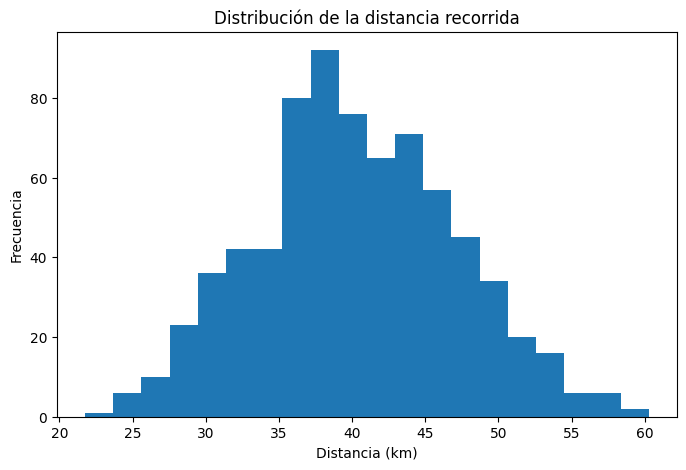

In [8]:
plt.figure(figsize=(8,5))
plt.hist(df_limpio["distancia_km"].dropna(), bins=20)
plt.title("Distribución de la distancia recorrida")
plt.xlabel("Distancia (km)")
plt.ylabel("Frecuencia")
plt.show()


## 6. Distribución de los residuos recolectados

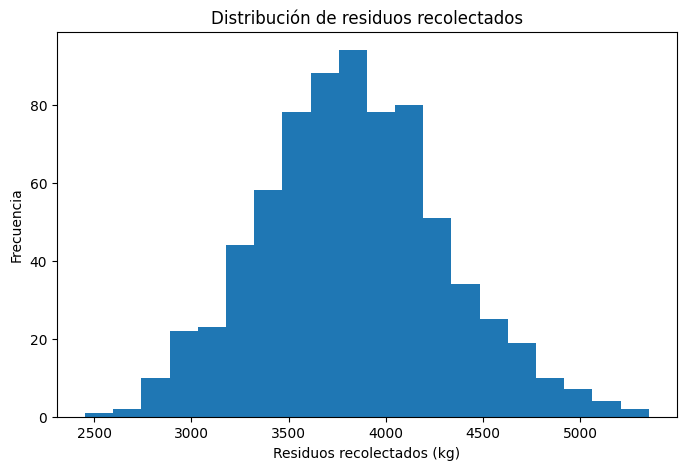

In [9]:
plt.figure(figsize=(8,5))
plt.hist(df_limpio["residuos_recolectados_kg"].dropna(), bins=20)
plt.title("Distribución de residuos recolectados")
plt.xlabel("Residuos recolectados (kg)")
plt.ylabel("Frecuencia")
plt.show()


## 7. Distancia recorrida y consumo de combustible

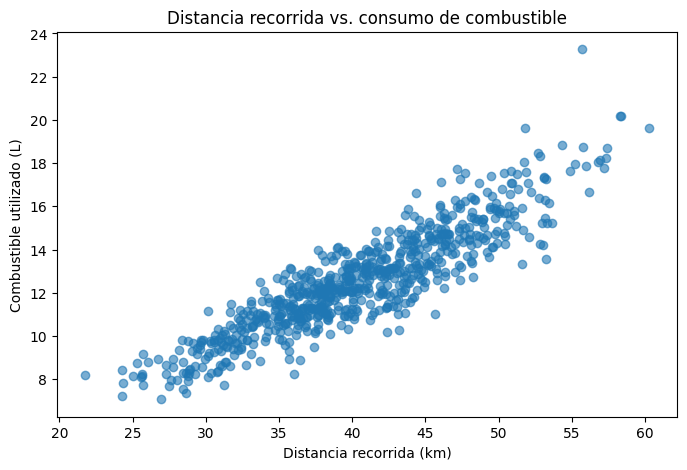

In [10]:
plt.figure(figsize=(8,5))
plt.scatter(df_limpio["distancia_km"], df_limpio["combustible_l"], alpha=0.6)
plt.title("Distancia recorrida vs. consumo de combustible")
plt.xlabel("Distancia recorrida (km)")
plt.ylabel("Combustible utilizado (L)")
plt.show()


## 8. Distancia recorrida y costo operativo

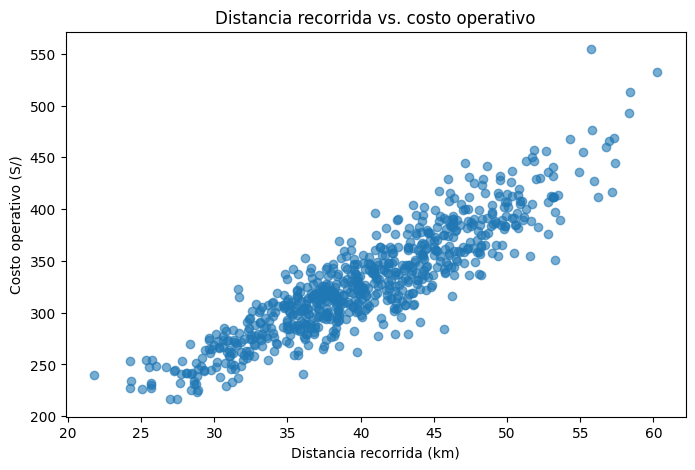

In [11]:
plt.figure(figsize=(8,5))
plt.scatter(df_limpio["distancia_km"], df_limpio["costo_operativo_soles"], alpha=0.6)
plt.title("Distancia recorrida vs. costo operativo")
plt.xlabel("Distancia recorrida (km)")
plt.ylabel("Costo operativo (S/)")
plt.show()


## 9. Matriz de correlaciones

In [12]:
correlaciones = df_limpio[variables_numericas].corr()
correlaciones.round(2)


,duracion_min,distancia_km,combustible_l,costo_operativo_soles,capacidad_vehicular_kg,residuos_recolectados_kg,puntos_programados,puntos_atendidos,cumplimiento_pct
duracion_min,1.00,0.65,0.58,0.73,-0.02,0.24,0.00,0.01,0.03
distancia_km,0.65,1.00,0.90,0.90,0.03,0.34,-0.03,-0.02,0.04
combustible_l,0.58,0.90,1.00,0.97,0.04,0.28,-0.04,-0.03,0.04
costo_operativo_soles,0.73,0.90,0.97,1.00,0.03,0.28,-0.02,-0.02,0.04
capacidad_vehicular_kg,-0.02,0.03,0.04,0.03,1.00,0.23,-0.03,-0.04,-0.07
residuos_recolectados_kg,0.24,0.34,0.28,0.28,0.23,1.00,0.00,0.00,-0.01
puntos_programados,0.00,-0.03,-0.04,-0.02,-0.03,0.00,1.00,0.99,0.09
puntos_atendidos,0.01,-0.02,-0.03,-0.02,-0.04,0.00,0.99,1.00,0.26
cumplimiento_pct,0.03,0.04,0.04,0.04,-0.07,-0.01,0.09,0.26,1.00


## 10. Análisis por ruta

In [13]:
resumen_ruta = (
    df_limpio.groupby("codigo_ruta")
    .agg(
        recorridos=("codigo_ruta", "size"),
        distancia_promedio_km=("distancia_km", "mean"),
        duracion_promedio_min=("duracion_min", "mean"),
        combustible_promedio_l=("combustible_l", "mean"),
        residuos_promedio_kg=("residuos_recolectados_kg", "mean"),
        cumplimiento_promedio_pct=("cumplimiento_pct", "mean")
    )
    .round(2)
)

resumen_ruta


,recorridos,distancia_promedio_km,duracion_promedio_min,combustible_promedio_l,residuos_promedio_kg,cumplimiento_promedio_pct
codigo_ruta,,,,,,
R001,122,34.02,172.49,10.47,"3,501.40",98.53
R002,121,36.77,182.55,11.51,"3,602.98",98.41
R003,121,39.78,194.21,12.34,"3,752.09",98.39
R004,122,40.24,196.81,12.48,"3,903.82",97.95
R005,122,43.72,218.65,13.45,"4,031.36",98.35
R006,122,47.22,232.83,14.84,"4,207.36",98.75


## 11. Análisis temporal

In [14]:
df_limpio["fecha"] = pd.to_datetime(df_limpio["fecha"])
df_limpio["mes"] = df_limpio["fecha"].dt.month

resumen_mes = (
    df_limpio.groupby("mes")
    .agg(
        residuos_total_kg=("residuos_recolectados_kg", "sum"),
        distancia_total_km=("distancia_km", "sum"),
        combustible_total_l=("combustible_l", "sum"),
        cumplimiento_promedio_pct=("cumplimiento_pct", "mean")
    )
    .round(2)
)

resumen_mes


,residuos_total_kg,distancia_total_km,combustible_total_l,cumplimiento_promedio_pct
mes,,,,
1,"248,584.98","2,498.02",771.66,98.30
2,"222,127.35","2,276.70",699.87,98.14
3,"232,866.80","2,489.54",760.36,98.16
4,"223,268.99","2,402.26",748.62,98.67
5,"237,682.34","2,486.89",764.72,98.08
6,"231,279.98","2,456.61",751.53,98.34
7,"241,085.81","2,451.51",749.16,98.75
8,"229,589.11","2,531.60",789.92,98.22
9,"227,511.42","2,353.03",735.77,98.64


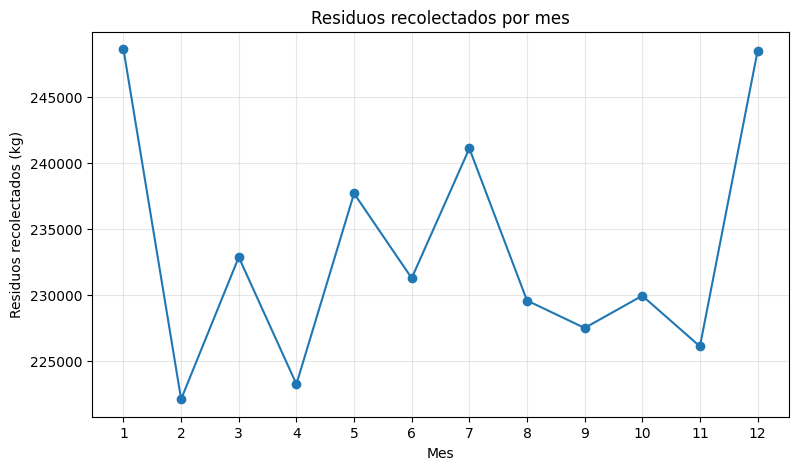

In [15]:
plt.figure(figsize=(9,5))
plt.plot(resumen_mes.index, resumen_mes["residuos_total_kg"], marker="o")
plt.title("Residuos recolectados por mes")
plt.xlabel("Mes")
plt.ylabel("Residuos recolectados (kg)")
plt.xticks(range(1,13))
plt.grid(True, alpha=0.3)
plt.show()


## 12. Revisión de valores atípicos

In [16]:
# Método IQR como apoyo exploratorio.
# Un valor atípico no debe eliminarse automáticamente; puede representar una incidencia real.

def detectar_atipicos_iqr(serie):
    s = serie.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return s[(s < limite_inferior) | (s > limite_superior)]

for variable in ["distancia_km", "duracion_min", "combustible_l", "residuos_recolectados_kg"]:
    atipicos = detectar_atipicos_iqr(df_limpio[variable])
    print(variable, "->", len(atipicos), "posibles valores atípicos")


distancia_km -> 2 posibles valores atípicos
duracion_min -> 7 posibles valores atípicos
combustible_l -> 8 posibles valores atípicos
residuos_recolectados_kg -> 6 posibles valores atípicos


## 13. Conclusiones del EDA

El análisis exploratorio permite verificar la estructura de la base y reconocer la relación existente entre las principales variables operativas del servicio. La distancia recorrida, el tiempo de operación, el consumo de combustible, el costo operativo y la cantidad de residuos recolectados constituyen indicadores relevantes para la etapa de modelamiento.

También se identifican valores faltantes y registros duplicados, por lo que la depuración de la información constituye una etapa necesaria antes del entrenamiento de modelos predictivos.

Los posibles valores atípicos deben revisarse junto con las incidencias operativas, ya que pueden corresponder a hechos reales como congestión, desperfectos, vías en mal estado o acumulaciones extraordinarias.

Este EDA constituye la etapa previa para desarrollar posteriormente modelos de aprendizaje automático orientados a predecir la demanda de residuos y alimentar el módulo de optimización combinatoria de rutas.
